# Análisis Estadístico — Ecorregímenes CAP 2023/2024

**Objetivo:** explorar los datasets procesados y extraer estadísticas sobre
ecorregímenes, pagos, parcelas y agricultores.

**Datos:** ~5.4M filas por año, 21 columnas. Motor: **DuckDB** (columnar, sin carga en RAM).

**Convención:** todas las consultas filtran por `CORRECTLY_PROCESSED = 'OK'` salvo indicación contraria.

# Introducción: 

## Significado de las columnas

El archivo final tiene **21 columnas**. Las primeras 14 provienen del merge de los dos archivos de entrada (AYUDAS + SUPERFICIES) y las 7 últimas las añade la etapa `process`.

**Los importes de ecorrégimen se han calculado con las tasas definitivas oficiales fijadas para 2023 y 2024**, almacenadas en `data/classification_2023.json` y `data/classification_2024.json`.

## Columnas 1–4: Identificación de la línea de ayuda (de AYUDAS)

| # | Columna | Tipo / Formato | Qué guarda |
|---|---------|---------------|------------|
| 1 | `SECUENCIAL` | entero | Número de secuencia del agricultor/solicitante. Agrupa todas las parcelas de una misma solicitud. |
| 2 | `REC_CODIGO` | entero | Código de registro, **único por línea de ayuda**. Es la clave primaria de la fila. |
| 3 | `LNA_CODIGO` | entero | Código de la línea de ayuda. **500–512 = ecoesquemas**; el resto (18, 213, 215, 9010xxx…) son otras ayudas (ABRS, etc.). |
| 4 | `DESC_LNA` | texto | Descripción en español de la línea de ayuda (ej. "Ayuda básica a la renta para la sostenibilidad (ABRS)", "Cubierta inerte de restos de poda"). |

## Columnas 5–11: Identificación catastral y cultivo (de SUPERFICIES)

| # | Columna | Tipo / Formato | Qué guarda |
|---|---------|---------------|------------|
| 5 | `PRO_CODIGO` | texto, 2 dígitos | Código de provincia (ej. "14" = Córdoba). |
| 6 | `MSP_CODIGO` | texto, 3 dígitos | Código de municipio (ej. "048"). |
| 7 | `REC_POLIGONO` | texto, 3 dígitos | Número de polígono catastral (ej. "001"). |
| 8 | `REC_PARCELA` | texto, 5 dígitos | Número de parcela (ej. "00199"). |
| 9 | `REC_RECINTO` | texto, 1 dígito | Número de recinto dentro de la parcela (ej. "1"). |
| 10 | `PRD_CODIGO` | entero | Código de producto/cultivo (ej. 101 = olivo). |
| 11 | `PRD_DESC` | texto | Descripción del cultivo (ej. "OLIVO", "PASTOS PERMANENTES DE 5 O MÁS AÑOS"). |

> **Nota:** La referencia catastral completa se forma como `PRO/MSP/POLIGONO/PARCELA` (ej. "14/048/001/00199"). Es la clave que se usa para buscar la pendiente en SIGPAC.

## Columnas 12–14: Superficies (de SUPERFICIES)

| # | Columna | Tipo / Formato | Qué guarda |
|---|---------|---------------|------------|
| 12 | `SUP_SECANO_HA` | float | Superficie en **secano** (hectáreas). |
| 13 | `SUP_RIEGO_HA` | float | Superficie en **regadío** (hectáreas). |
| 14 | `SUP_TOTAL_HA` | float | Superficie **total** (secano + regadío, hectáreas). |

> **Nota:** Si una fila tiene las tres superficies en NULL, es que no encajó en el merge con SUPERFICIES → se marca como `FAILED`.

## Columnas 15–21: Añadidas por la etapa `process`

| # | Columna | Tipo / Formato | Qué guarda |
|---|---------|---------------|------------|
| 15 | `%_PENDIENTE_MEDIA` | texto (ej. "15.5%") | Pendiente media de la parcela según SIGPAC. **Solo se rellena para LNA 510/511** (cubiertas vegetales), porque son las únicas que dependen de la pendiente. Vacío en el resto. |
| 16 | `ECORREGIMEN_CODIGO` | texto | Código del ecorrégimen asignado. Valores posibles: `P1` (pastoreo y biodiversidad), `P3/P4` (rotación y siembra directa), `P5 (A)` (espacios de biodiversidad en cultivos), `P5 (B)` (espacios de biodiversidad bajo agua), `P6/P7` (cubiertas vegetales). Vacío si no es ecoesquema o si falló. |
| 17 | `PENINSULAR_PAGO_BASE` | float (€) | Importe del pago en régimen **peninsular**, sin pluriannualidad. |
| 18 | `PENINSULAR_PAGO_PLURI` | float (€) | Importe del pago en régimen **peninsular**, con pluriannualidad (+25 €/ha). |
| 19 | `INSULAR_PAGO_BASE` | float (€) | Importe del pago en régimen **insular**, sin pluriannualidad. |
| 20 | `INSULAR_PAGO_PLURI` | float (€) | Importe del pago en régimen **insular**, con pluriannualidad. |
| 21 | `CORRECTLY_PROCESSED` | texto | Estado del procesamiento. Valores: `OK` (éxito), `NOT_ECOSHEME` (no es ecoesquema), `API_DATA_MISSING` (sin pendiente en SIGPAC), `FAILED` (superficie NULL), `PENDIENTE_CLASIFICACION` (sin tasas en el JSON), o heredados `Y`/`N`/vacío. |

> **Nota sobre los pagos:** El cálculo es por tiers: si la superficie es ≤ al umbral (`Threshold_ha`) se aplica `Tier_1`; si es mayor, se aplica `Tier_1` hasta el umbral y `Tier_2` al excedente. La pluriannualidad añade 25 €/ha a la tasa.

## 1. Carga de datos

In [7]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

BASE = Path("..")
OUT  = BASE / "out"
YEARS = [2023, 2024]

PROVINCIAS = {
    "04": "Alicante", "11": "Córdoba", "14": "Granada",
    "18": "Jaén",     "21": "Málaga",   "23": "Murcia",
    "29": "Sevilla",  "41": "Zaragoza",
}

con = duckdb.connect()

def crear_vista(nombre: str, year: int):
    path = OUT / f"PAC_{year}_PROCESSED_SORTED.csv"
    con.execute(f"""
        CREATE OR REPLACE VIEW {nombre} AS
        SELECT
            SECUENCIAL, REC_CODIGO, LNA_CODIGO, DESC_LNA,
            PRO_CODIGO, MSP_CODIGO, PRD_CODIGO, PRD_DESC,
            CAST(SUP_SECANO_HA  AS DOUBLE) AS SUP_SECANO_HA,
            CAST(SUP_RIEGO_HA   AS DOUBLE) AS SUP_RIEGO_HA,
            CAST(SUP_TOTAL_HA   AS DOUBLE) AS SUP_TOTAL_HA,
            CASE
                WHEN "%_PENDIENTE_MEDIA" IS NULL OR "%_PENDIENTE_MEDIA" = ''
                THEN NULL
                ELSE CAST(REPLACE("%_PENDIENTE_MEDIA", '%', '') AS DOUBLE)
            END AS PENDIENTE_MEDIA,
            ECORREGIMEN_CODIGO,
            CAST(PENINSULAR_PAGO_BASE  AS DOUBLE) AS PEN_PAGO_BASE,
            CAST(PENINSULAR_PAGO_PLURI AS DOUBLE) AS PEN_PAGO_PLURI,
            CAST(INSULAR_PAGO_BASE     AS DOUBLE) AS INS_PAGO_BASE,
            CAST(INSULAR_PAGO_PLURI    AS DOUBLE) AS INS_PAGO_PLURI,
            CORRECTLY_PROCESSED AS STATUS
        FROM read_csv_auto(
            '{path}', header=True, encoding='UTF-8',
            quote='"', sample_size=-1
        )
    """)
    return path

for year in YEARS:
    vista = f"cap_{year}"
    path  = crear_vista(vista, year)
    n = con.execute(f"SELECT COUNT(*) FROM {vista}").fetchone()[0]
    print(f"  {vista}: {n:,} filas  ({path.name})")

print("Vistas creadas. Listo para el análisis.")

  cap_2023: 5,397,599 filas  (PAC_2023_PROCESSED_SORTED.csv)
  cap_2024: 5,351,966 filas  (PAC_2024_PROCESSED_SORTED.csv)
Vistas creadas. Listo para el análisis.


## 2. Calidad de datos y estado del pipeline

Cada fila tiene un `STATUS` que indica cómo se procesó.
Valores: `OK`, `NOT_ECOSHEME`, `PENDIENTE_CLASIFICACION`, `API_DATA_MISSING`, `FAILED`.
También hay valores legacy (`Y`, `N`, `NaN`) de ejecuciones previas.

| Valor | 2023 | 2024 | ¿Qué significa? | ¿Éxito / fallo / inofensivo? |
|---|---|---|---|---|
| `NOT_ECOSHEME` | 3.533.616 (65,5 %) | 3.517.539 (65,7 %) | La línea de ayuda (LNA_CODIGO) **no está en el rango de ecoesquemas** (500–512). No le toca ningún cálculo: sin pendiente, sin ecorrégimen, sin pagos. | **Inofensivo / esperado.** No es un fallo, es el caso normal para la mayoría de filas (ABRS, pagos básicos, etc.). |
| `OK` | 1.807.292 (33,5 %) | 1.800.484 (33,6 %) | **Éxito completo**: se clasificó el ecoesquema (ecorrégimen) y se calcularon los 4 pagos (peninsular/insular × base/pluri). | **Éxito.** |
| `Y` | 15.217 (0,28 %) | 6.999 (0,13 %) | Heredado del código anterior: **también es éxito** (clasificado + pagos calculados). Verifiqué: 100 % de estas filas tienen ecorrégimen y pagos rellenos. | **Éxito** (equivalente antiguo de `OK`). |
| `NULL` (vacío) | 24.490 (0,45 %) | 12.795 (0,24 %) | Heredado del código antiguo para filas **no-ecoesquema** (son todas LNA fuera de 500–512: 18, 215, 213, 9010xxx…). | **Inofensivo** (equivalente antiguo de `NOT_ECOSHEME`). |
| `API_DATA_MISSING` | 9.432 (0,17 %) | 7.255 (0,14 %) | Solo LNA 510/511: la parcela **no tiene pendiente en la caché SIGPAC** (la API falló tras 3 reintentos en el prefetch, o la parcela no existe en SIGPAC). Sin pendiente no se puede elegir el ecorrégimen adecuado de cubiertas vegetales. | **Fallo real (reparable).** Son las ~5.599 (2023) / 5.583 (2024) parcelas con error en el prefetch, que afectan a más filas de las que hay parcelas. |
| `FAILED` | 7.259 (0,13 %) | 6.688 (0,12 %) | **Fallo de datos**: superficie NULL en el merge (la fila no encajó con SUPERFICIES) o `LNA_CODIGO` no numérico. Verifiqué: las filas FAILED tienen `SUP_SECANO_HA`, `SUP_RIEGO_HA` y `SUP_TOTAL_HA` en NULL. | **Fallo real (de datos de entrada).** |
| `N` | 293 (0,01 %) | 206 (0,00 %) | Heredado del código antiguo: **fallo** (no clasificó, sin pagos). | **Fallo real.** |
| `PENDIENTE_CLASIFICACION` | 0 | 0 | Previsto para 506/507 si no tuvieran tasas en el JSON. **No aparece** porque 506/507 ya están en `classification_*.json` (506: 151/87 filas OK; 507: 693/3). | No presente en los datos. |



In [8]:
resumen = []
for year in YEARS:
    df = con.execute(f"""
        SELECT STATUS,
               COUNT(*)                    AS filas,
               COUNT(DISTINCT SECUENCIAL)  AS agricultores
        FROM cap_{year}
        GROUP BY 1 ORDER BY 2 DESC
    """).fetchdf()
    df["year"] = year
    df["pct"] = (100.0 * df["filas"] / df["filas"].sum()).round(1)
    resumen.append(df)

resumen = pd.concat(resumen, ignore_index=True)
pd.set_option("display.float_format", "{:,.0f}".format)
resumen[["year", "STATUS", "filas", "pct", "agricultores"]]

,year,STATUS,filas,pct,agricultores
0,2023,NOT_ECOSHEME,3533616,66,214557
1,2023,OK,1807292,34,184691
2,2023,NaN,24490,0,2580
3,2023,Y,15217,0,2190
4,2023,API_DATA_MISSING,9432,0,5417
5,2023,FAILED,7259,0,401
6,2023,N,293,0,88
7,2024,NOT_ECOSHEME,3517539,66,210264
8,2024,OK,1800484,34,181235
9,2024,NaN,12795,0,1181


In [9]:
for year in YEARS:
    df = con.execute(f"""
        SELECT STATUS, LNA_CODIGO, COUNT(*) AS n
        FROM cap_{year}
        WHERE STATUS IN ('Y', 'N') OR STATUS IS NULL
        GROUP BY 1, 2 ORDER BY 1, 3 DESC
    """).fetchdf()
    print(f"\n=== {year} ===")
    print(df.to_string(index=False) if not df.empty else "  (vacío)")


=== 2023 ===
STATUS  LNA_CODIGO     n
     N         505   201
     N         510    60
     N         511    32
     Y         510 10049
     Y         511  3531
     Y         509  1471
     Y         512   161
     Y         508     5
   NaN          18 19113
   NaN         215  3849
   NaN     9010146   368
   NaN         213   336
   NaN     9010147   229
   NaN     9010138   123
   NaN     9010142   123
   NaN     9010113   105
   NaN         209    62
   NaN     9010133    62
   NaN         216    47
   NaN     9010134    19
   NaN     9010148    12
   NaN         212    10
   NaN     9010151     9
   NaN     9010136     6
   NaN         211     6
   NaN     9010135     5
   NaN     9010130     3
   NaN         214     3

=== 2024 ===
STATUS  LNA_CODIGO    n
     N         505  165
     N         510   33
     N         511    8
     Y         510 5088
     Y         511 1215
     Y         509  432
     Y         512  263
     Y         508    1
   NaN          18 8774
   NaN 

In [10]:
for year in YEARS:
    total = con.execute(f"SELECT COUNT(*) FROM cap_{year}").fetchone()[0]
    ok    = con.execute(f"SELECT COUNT(*) FROM cap_{year} WHERE STATUS = 'OK'").fetchone()[0]
    print(f"  {year}: total={total:,}  OK={ok:,}  ({100*ok/total:.1f}%)")

  2023: total=5,397,599  OK=1,807,292  (33.5%)
  2024: total=5,351,966  OK=1,800,484  (33.6%)


## 3. Distribución de ecorregímenes

| Código | Ecorregimen | LNA origen |
|--------|-------------|------------|
| P1 | Pastoreo extensivo | 505 |
| P3/P4 | Siembra directa / Rotación | 508, 509 |
| P5 (A) | Biodiversidad (secano/riego) | 512 |
| P5 (B) | Biodiversidad (bajo agua) | 506, 507 |
| P6/P7 | Cubierta vegetal / inerte | 510, 511 |

In [11]:
eco = []
for year in YEARS:
    df = con.execute(f"""
        SELECT ECORREGIMEN_CODIGO AS ecorregimen,
               COUNT(*)                    AS filas,
               COUNT(DISTINCT SECUENCIAL)  AS agricultores,
               ROUND(SUM(SUP_TOTAL_HA), 0) AS hectareas
        FROM cap_{year} WHERE STATUS = 'OK'
        GROUP BY 1 ORDER BY 4 DESC
    """).fetchdf()
    df["year"] = year
    eco.append(df)

eco = pd.concat(eco, ignore_index=True)
eco[["year", "ecorregimen", "filas", "agricultores", "hectareas"]]

,year,ecorregimen,filas,agricultores,hectareas
0,2023,P6/P7,1308235,158466,"1,488,067"
1,2023,P1,147735,7487,"1,333,590"
2,2023,P3/P4,274117,31029,"966,050"
3,2023,P5 (A),76361,5742,"194,195"
4,2023,P5 (B),844,61,"11,110"
5,2024,P6/P7,1284155,154349,"1,458,991"
6,2024,P1,151918,7310,"1,327,419"
7,2024,P3/P4,273571,30379,"939,266"
8,2024,P5 (A),90750,6982,"192,108"
9,2024,P5 (B),90,13,"1,088"


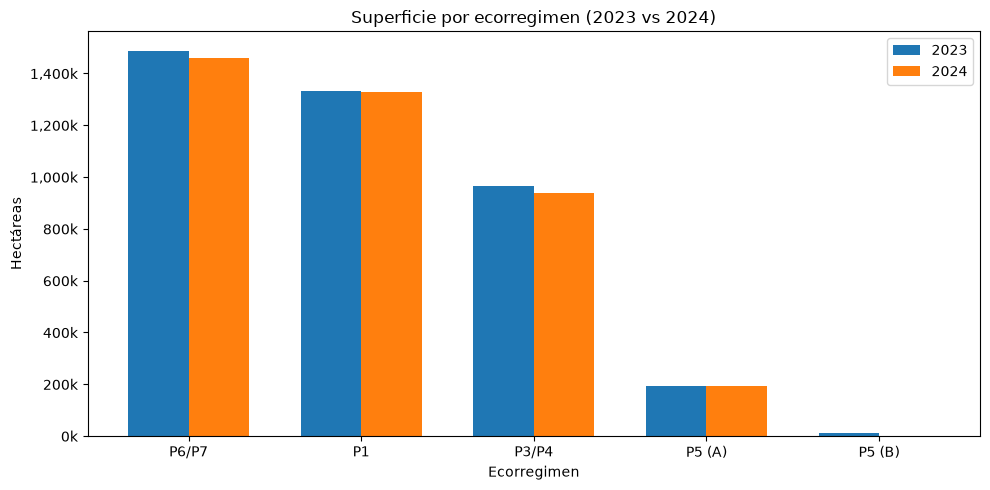

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(eco[eco["year"]==2023]["ecorregimen"]))
width = 0.35
for i, year in enumerate(YEARS):
    sub = eco[eco["year"]==year].set_index("ecorregimen").reindex(eco[eco["year"]==2023]["ecorregimen"])
    ax.bar(x + i*width, sub["hectareas"], width, label=str(year))
ax.set_xlabel("Ecorregimen")
ax.set_ylabel("Hectáreas")
ax.set_title("Superficie por ecorregimen (2023 vs 2024)")
ax.set_xticks(x + width/2)
ax.set_xticklabels(eco[eco["year"]==2023]["ecorregimen"])
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
plt.tight_layout()
plt.show()

In [13]:
lna = con.execute("""
    SELECT LNA_CODIGO, DESC_LNA, ECORREGIMEN_CODIGO,
           COUNT(*) AS filas,
           COUNT(DISTINCT SECUENCIAL) AS agricultores
    FROM cap_2023 WHERE STATUS = 'OK'
    GROUP BY 1, 2, 3 ORDER BY 4 DESC
""").fetchdf()

## 4. Distribución geográfica y por cultivo

8 provincias del sur/centro de España. El cultivo se identifica por `PRD_DESC`.

In [14]:
prov = con.execute("""
    SELECT PRO_CODIGO,
           COUNT(*)                    AS filas,
           COUNT(DISTINCT SECUENCIAL)  AS agricultores,
           ROUND(SUM(SUP_TOTAL_HA), 0) AS hectareas
    FROM cap_2023 WHERE STATUS = 'OK'
    GROUP BY 1 ORDER BY 3 DESC
""").fetchdf()
prov["provincia"] = prov["PRO_CODIGO"].map(PROVINCIAS)
prov[["provincia", "PRO_CODIGO", "agricultores", "hectareas"]]

,provincia,PRO_CODIGO,agricultores,hectareas
0,Murcia,23,76444,"698,300"
1,Granada,14,36513,"864,095"
2,Jaén,18,26877,"456,304"
3,Zaragoza,41,23216,"905,056"
4,Sevilla,29,14077,"236,340"
5,Córdoba,11,6717,"421,038"
6,Málaga,21,5175,"328,673"
7,Alicante,04,2799,"83,206"


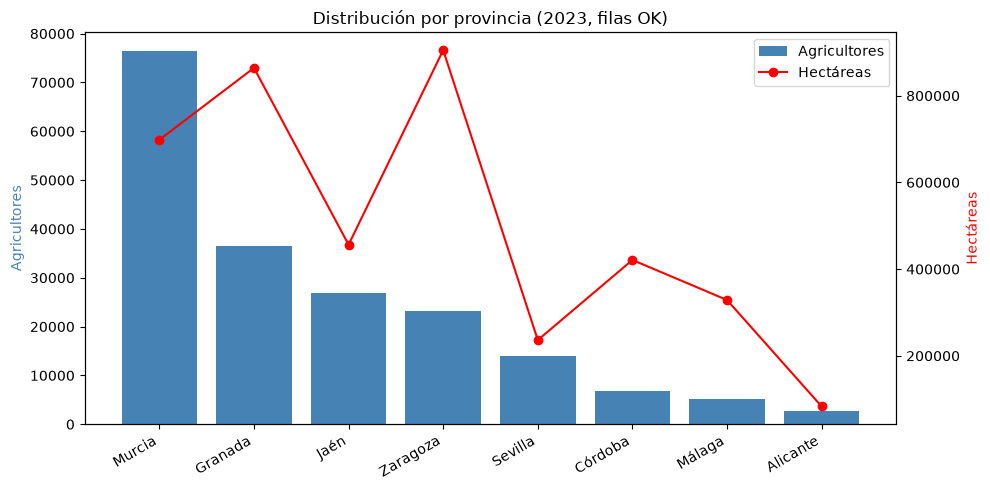

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(prov))
ax1.bar(x, prov["agricultores"], color="steelblue", label="Agricultores")
ax1.set_ylabel("Agricultores", color="steelblue")
ax1.set_xticks(x)
ax1.set_xticklabels(prov["provincia"], rotation=30, ha="right")
ax2 = ax1.twinx()
ax2.plot(x, prov["hectareas"], "ro-", label="Hectáreas")
ax2.set_ylabel("Hectáreas", color="red")
ax1.set_title("Distribución por provincia (2023, filas OK)")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
plt.tight_layout()
plt.show()

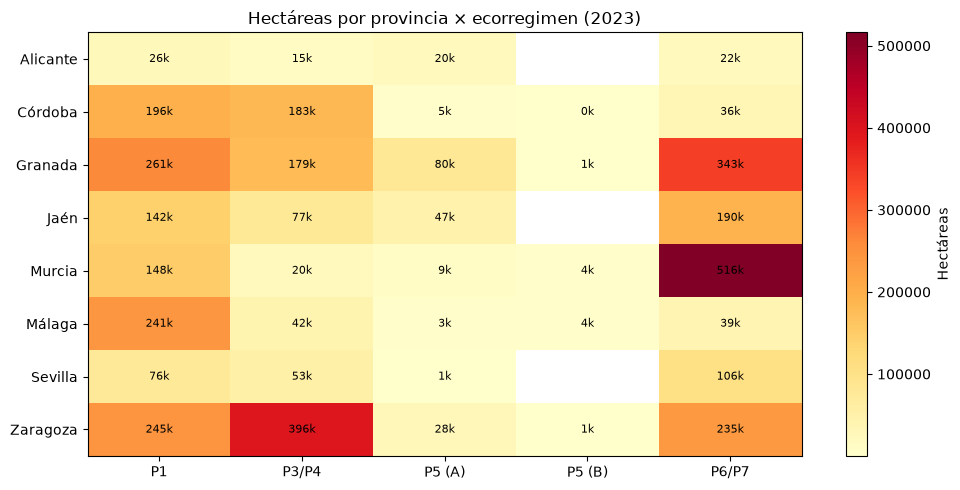

In [16]:
piv = con.execute("""
    SELECT PRO_CODIGO, ECORREGIMEN_CODIGO, SUM(SUP_TOTAL_HA) AS ha
    FROM cap_2023 WHERE STATUS = 'OK'
    GROUP BY 1, 2
""").fetchdf().pivot(index="PRO_CODIGO", columns="ECORREGIMEN_CODIGO", values="ha")
piv.index = piv.index.map(lambda p: PROVINCIAS.get(p, p))
piv = piv.sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(piv.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(piv.columns)))
ax.set_xticklabels(piv.columns)
ax.set_yticks(range(len(piv.index)))
ax.set_yticklabels(piv.index)
ax.set_title("Hectáreas por provincia × ecorregimen (2023)")
fig.colorbar(im, ax=ax, label="Hectáreas")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if v > 0:
            ax.text(j, i, f"{v/1000:.0f}k", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
crops = con.execute("""
    SELECT PRD_DESC,
           COUNT(*)                    AS filas,
           COUNT(DISTINCT SECUENCIAL)  AS agricultores,
           ROUND(SUM(SUP_TOTAL_HA), 0) AS hectareas
    FROM cap_2023 WHERE STATUS = 'OK'
    GROUP BY 1 ORDER BY 4 DESC LIMIT 10
""").fetchdf()
crops

,PRD_DESC,filas,agricultores,hectareas
0,OLIVO,1217331,153690,"1,306,327"
1,PASTOS PERMANENTES DE 5 O MÁS AÑOS,137384,7442,"1,290,394"
2,GIRASOL,39380,10104,"188,653"
3,TRIGO DURO,37295,9577,"184,592"
4,BARBECHO TRADICIONAL,58932,12531,"166,478"
5,ALMENDRO,68179,10743,"122,934"
6,TRIGO BLANDO,30871,7451,"114,750"
7,CEBADA,31974,7905,"95,900"
8,AVENA,30156,6943,"78,875"
9,PASTOS DE MENOS DE 5 AÑOS,11199,1918,"54,316"


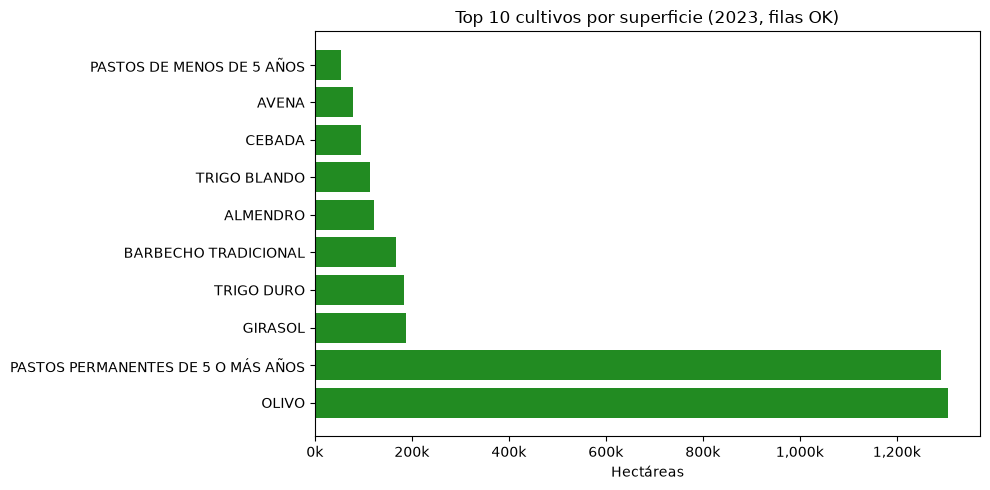

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(range(len(crops)), crops["hectareas"], color="forestgreen")
ax.set_yticks(range(len(crops)))
ax.set_yticklabels(crops["PRD_DESC"])
ax.set_xlabel("Hectáreas")
ax.set_title("Top 10 cultivos por superficie (2023, filas OK)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
plt.tight_layout()
plt.show()

## 5. Tamaño de parcela y pendiente

La pendiente (`PENDIENTE_MEDIA`) solo tiene valor para LNA 510/511 (dependen de SIGPAC).
El tamaño se mide en `SUP_TOTAL_HA`.

In [19]:
size = con.execute("""
    SELECT
        CASE
            WHEN SUP_TOTAL_HA < 1  THEN '<1 ha'
            WHEN SUP_TOTAL_HA < 5  THEN '1-5 ha'
            WHEN SUP_TOTAL_HA < 10 THEN '5-10 ha'
            WHEN SUP_TOTAL_HA < 25 THEN '10-25 ha'
            WHEN SUP_TOTAL_HA < 50 THEN '25-50 ha'
            ELSE '50+ ha'
        END AS tamano,
        COUNT(*)                    AS filas,
        COUNT(DISTINCT SECUENCIAL)  AS agricultores,
        ROUND(SUM(SUP_TOTAL_HA), 0) AS hectareas
    FROM cap_2023 WHERE STATUS = 'OK'
    GROUP BY 1 ORDER BY MIN(SUP_TOTAL_HA)
""").fetchdf()
size

,tamano,filas,agricultores,hectareas
0,<1 ha,1234848,162654,"354,439"
1,1-5 ha,416244,126236,"911,336"
2,5-10 ha,79848,35514,"557,437"
3,10-25 ha,52402,20332,"800,905"
4,25-50 ha,15927,8014,"543,817"
5,50+ ha,8023,4168,"825,079"


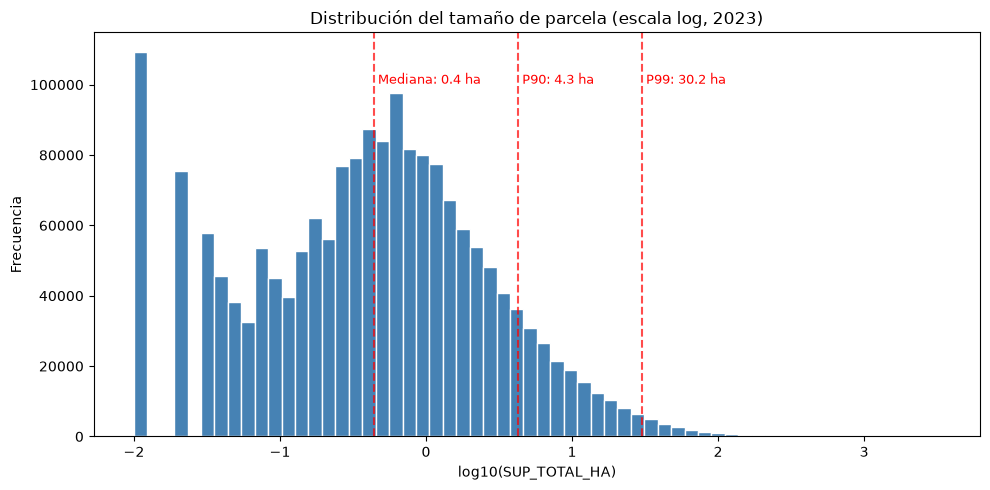

In [20]:
ha = con.execute("""
    SELECT SUP_TOTAL_HA FROM cap_2023
    WHERE STATUS = 'OK' AND SUP_TOTAL_HA > 0
""").fetchdf()["SUP_TOTAL_HA"].values

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(np.log10(ha), bins=60, color="steelblue", edgecolor="white")
ax.set_xlabel("log10(SUP_TOTAL_HA)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución del tamaño de parcela (escala log, 2023)")
for p, label in [(50, "Mediana"), (90, "P90"), (99, "P99")]:
    v = np.percentile(ha, p)
    ax.axvline(np.log10(v), color="red", linestyle="--", alpha=0.7)
    ax.text(np.log10(v), ax.get_ylim()[1]*0.9, f" {label}: {v:.1f} ha",
            color="red", fontsize=9, va="top")
plt.tight_layout()
plt.show()

In [21]:
slope = con.execute("""
    SELECT ECORREGIMEN_CODIGO,
           COUNT(*) AS n,
           ROUND(AVG(PENDIENTE_MEDIA), 1)    AS media,
           ROUND(MEDIAN(PENDIENTE_MEDIA), 1) AS mediana,
           ROUND(quantile_cont(PENDIENTE_MEDIA, 0.25), 1) AS p25,
           ROUND(quantile_cont(PENDIENTE_MEDIA, 0.75), 1) AS p75,
           ROUND(MIN(PENDIENTE_MEDIA), 1) AS min,
           ROUND(MAX(PENDIENTE_MEDIA), 1) AS max
    FROM cap_2023
    WHERE STATUS = 'OK' AND PENDIENTE_MEDIA IS NOT NULL
    GROUP BY 1 ORDER BY 3 DESC
""").fetchdf()
slope

,ECORREGIMEN_CODIGO,n,media,mediana,p25,p75,min,max
0,P6/P7,1308235,19,15,9,26,0,253


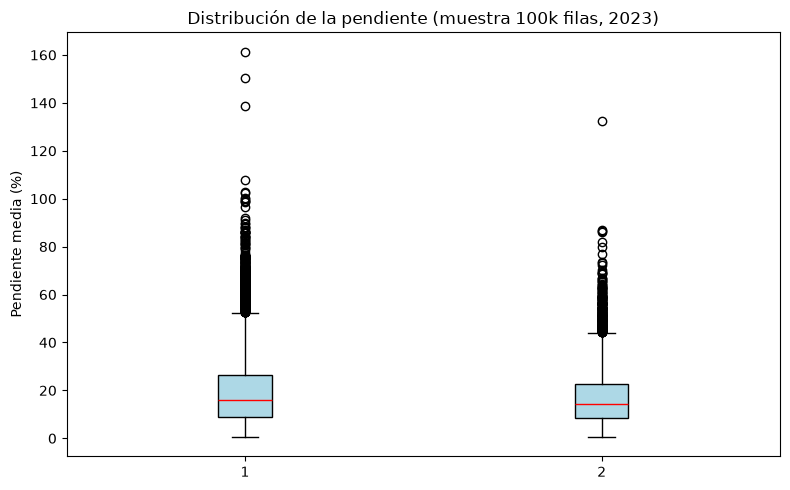

,LNA_CODIGO,DESC_LNA,ECORREGIMEN_CODIGO,filas,agricultores
0,510,Cubierta vegetal espontánea o sembrada,P6/P7,1077311,132923
1,509,Rotación de cultivos con especies mejorantes,P3/P4,271401,30825
2,511,Cubierta inerte de restos de poda,P6/P7,230924,31482
3,505,Pastoreo extensivo,P1,147735,7487
4,512,Espacios de biodiversidad,P5 (A),76361,5742
5,508,Siembra directa,P3/P4,2716,275
6,507,Islas de biodiversidad en pastos,P5 (B),693,38
7,506,Siega sostenible,P5 (B),151,23


In [22]:
sample = con.execute("""
    SELECT LNA_CODIGO, PENDIENTE_MEDIA
    FROM cap_2023
    WHERE STATUS = 'OK' AND PENDIENTE_MEDIA IS NOT NULL
    USING SAMPLE 100000 ROWS
""").fetchdf()

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    [sample[sample["LNA_CODIGO"]==510]["PENDIENTE_MEDIA"],
     sample[sample["LNA_CODIGO"]==511]["PENDIENTE_MEDIA"]],
    label=["510: Cubierta vegetal", "511: Cubierta inerta"],
    patch_artist=True, boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="red")
)
ax.set_ylabel("Pendiente media (%)")
ax.set_title("Distribución de la pendiente (muestra 100k filas, 2023)")
plt.tight_layout()
plt.show()

lna

## 6. Análisis de pagos

Cada fila OK tiene 4 columnas de pago (EUR): peninsular/insular × base/plurianual.

In [23]:
pagos = []
for year in YEARS:
    df = con.execute(f"""
        SELECT ECORREGIMEN_CODIGO AS ecorregimen,
               ROUND(SUM(PEN_PAGO_BASE),  0) AS pen_base,
               ROUND(SUM(PEN_PAGO_PLURI), 0) AS pen_pluri,
               ROUND(SUM(INS_PAGO_BASE),  0) AS ins_base,
               ROUND(SUM(INS_PAGO_PLURI), 0) AS ins_pluri,
               ROUND(SUM(SUP_TOTAL_HA), 0)   AS ha
        FROM cap_{year} WHERE STATUS = 'OK'
        GROUP BY 1 ORDER BY 2 DESC
    """).fetchdf()
    df["year"] = year
    pagos.append(df)

pagos = pd.concat(pagos, ignore_index=True)
pagos

,ecorregimen,pen_base,pen_pluri,ins_base,ins_pluri,ha,year
0,P6/P7,"185,424,787","222,626,346","290,016,656","327,218,383","1,488,067",2023
1,P3/P4,"62,963,738","87,114,980","100,126,055","124,277,300","966,050",2023
2,P1,"43,572,121","43,572,121","72,801,390","72,801,390","1,333,590",2023
3,P5 (A),"8,952,467","8,952,467","8,952,467","8,952,467","194,195",2023
4,P5 (B),"1,741,755","1,741,755","1,741,755","1,741,755","11,110",2023
5,P6/P7,"180,024,445","216,499,222","281,324,264","317,799,035","1,458,991",2024
6,P3/P4,"60,761,752","84,243,400","96,640,081","120,121,726","939,266",2024
7,P1,"45,852,026","45,852,026","74,952,648","74,952,648","1,327,419",2024
8,P5 (A),"9,328,781","9,328,781",0,0,"192,108",2024
9,P5 (B),"168,830","168,830","168,830","168,830","1,088",2024


In [24]:
eur_ha = con.execute("""
    SELECT ECORREGIMEN_CODIGO AS ecorregimen,
           ROUND(SUM(PEN_PAGO_BASE)  / SUM(SUP_TOTAL_HA), 2) AS pen_base_eur_ha,
           ROUND(SUM(PEN_PAGO_PLURI) / SUM(SUP_TOTAL_HA), 2) AS pen_pluri_eur_ha,
           ROUND(SUM(INS_PAGO_BASE)  / SUM(SUP_TOTAL_HA), 2) AS ins_base_eur_ha,
           ROUND(SUM(INS_PAGO_PLURI) / SUM(SUP_TOTAL_HA), 2) AS ins_pluri_eur_ha
    FROM cap_2023 WHERE STATUS = 'OK'
    GROUP BY 1 ORDER BY 2 DESC
""").fetchdf()
eur_ha

,ecorregimen,pen_base_eur_ha,pen_pluri_eur_ha,ins_base_eur_ha,ins_pluri_eur_ha
0,P5 (B),157,157,157,157
1,P6/P7,125,150,195,220
2,P3/P4,65,90,104,129
3,P5 (A),46,46,46,46
4,P1,33,33,55,55


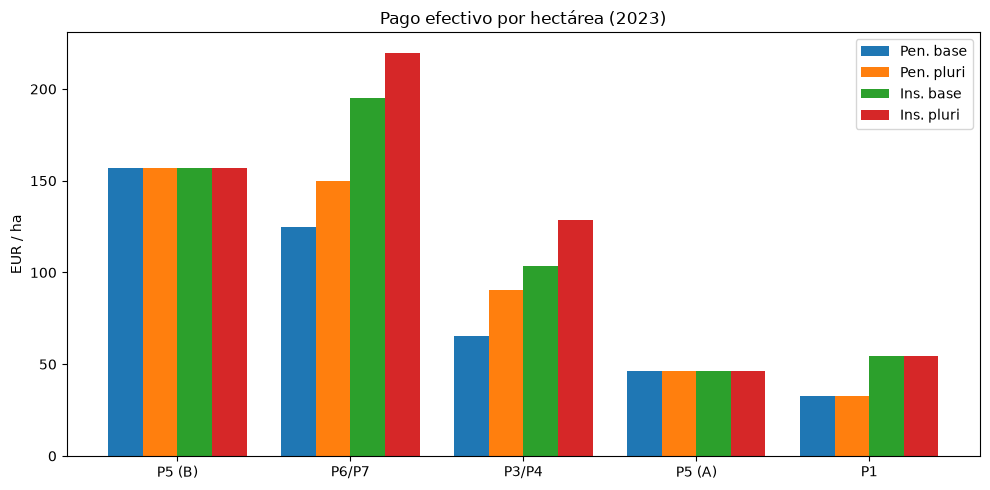

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(eur_ha))
width = 0.2
ax.bar(x - 1.5*width, eur_ha["pen_base_eur_ha"],  width, label="Pen. base")
ax.bar(x - 0.5*width, eur_ha["pen_pluri_eur_ha"], width, label="Pen. pluri")
ax.bar(x + 0.5*width, eur_ha["ins_base_eur_ha"],  width, label="Ins. base")
ax.bar(x + 1.5*width, eur_ha["ins_pluri_eur_ha"], width, label="Ins. pluri")
ax.set_xticks(x)
ax.set_xticklabels(eur_ha["ecorregimen"])
ax.set_ylabel("EUR / ha")
ax.set_title("Pago efectivo por hectárea (2023)")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
conc = con.execute("""
    WITH ha_farm AS (
        SELECT SECUENCIAL, SUM(SUP_TOTAL_HA) AS ha
        FROM cap_2023
        WHERE STATUS = 'OK'
        GROUP BY 1
    ),
    ranked AS (
        SELECT ha,
               SUM(ha) OVER (
                   ORDER BY ha DESC
                   ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
               ) AS cum_ha,
               SUM(ha) OVER () AS total_ha,
               ROW_NUMBER() OVER (ORDER BY ha DESC) AS rn
        FROM ha_farm
    )
    SELECT
        ROUND(100.0 * MAX(CASE WHEN rn <= 10  THEN cum_ha END) / MAX(total_ha), 1) AS top10,
        ROUND(100.0 * MAX(CASE WHEN rn <= 50  THEN cum_ha END) / MAX(total_ha), 1) AS top50,
        ROUND(100.0 * MAX(CASE WHEN rn <= 100 THEN cum_ha END) / MAX(total_ha), 1) AS top100
    FROM ranked
""").fetchdf()
print(f"Top 10 explotaciones:  {conc['top10'].iloc[0]}%")
print(f"Top 50 explotaciones:  {conc['top50'].iloc[0]}%")
print(f"Top 100 explotaciones: {conc['top100'].iloc[0]}%")

Top 10 explotaciones:  1.1%
Top 50 explotaciones:  3.4%
Top 100 explotaciones: 5.4%


## 7. Comparación interanual (2023 vs 2024)

Detectar cambios en superficie, número de agricultores y distribución por ecorregimen.

In [ ]:
yoy = con.execute("""
    SELECT '2023' AS year, COUNT(*) AS filas_ok,
           COUNT(DISTINCT SECUENCIAL) AS agricultores,
           ROUND(SUM(SUP_TOTAL_HA), 0) AS hectareas
    FROM cap_2023 WHERE STATUS = 'OK'
    UNION ALL
    SELECT '2024', COUNT(*), COUNT(DISTINCT SECUENCIAL), ROUND(SUM(SUP_TOTAL_HA), 0)
    FROM cap_2024 WHERE STATUS = 'OK'
""").fetchdf()
yoy["delta_filas"] = yoy["filas_ok"].iloc[1] - yoy["filas_ok"].iloc[0]
yoy["delta_agric"] = yoy["agricultores"].iloc[1] - yoy["agricultores"].iloc[0]
yoy["delta_ha"]    = yoy["hectareas"].iloc[1] - yoy["hectareas"].iloc[0]
yoy

,year,filas_ok,agricultores,hectareas,delta_filas,delta_agric,delta_ha
0,2023,1807292,184691,"3,993,012",-6808,-3456,"-74,140"
1,2024,1800484,181235,"3,918,872",-6808,-3456,"-74,140"


In [5]:
overlap = con.execute("""
    WITH f23 AS (SELECT DISTINCT SECUENCIAL FROM cap_2023 WHERE STATUS = 'OK'),
         f24 AS (SELECT DISTINCT SECUENCIAL FROM cap_2024 WHERE STATUS = 'OK')
    SELECT
        (SELECT COUNT(*) FROM f23) AS total_2023,
        (SELECT COUNT(*) FROM f24) AS total_2024,
        (SELECT COUNT(*) FROM f23 JOIN f24 USING (SECUENCIAL)) AS ambos_YEARS,
        (SELECT COUNT(*) FROM f23 WHERE SECUENCIAL NOT IN (SELECT SECUENCIAL FROM f24)) AS solo_2023,
        (SELECT COUNT(*) FROM f24 WHERE SECUENCIAL NOT IN (SELECT SECUENCIAL FROM f23)) AS solo_2024
""").fetchone()

print(f"  Agricultores 2023:      {overlap[0]:>10,}")
print(f"  Agricultores 2024:      {overlap[1]:>10,}")
print(f"  Comunes en ambos años:  {overlap[2]:>10,}  ({100*overlap[2]/overlap[0]:.1f}% de 2023)")
print(f"  No comunes (2023):      {overlap[3]:>10,}")
print(f"  No comunes (2024):      {overlap[4]:>10,}")

  Agricultores 2023:         184,691
  Agricultores 2024:         181,235
  Comunes en ambos años:     166,943  (90.4% de 2023)
  No comunes (2023):          17,748
  No comunes (2024):          14,292


In [ ]:
delta = con.execute("""
    WITH a23 AS (
        SELECT ECORREGIMEN_CODIGO AS eco, SUM(SUP_TOTAL_HA) AS ha
        FROM cap_2023 WHERE STATUS = 'OK' GROUP BY 1
    ),
    a24 AS (
        SELECT ECORREGIMEN_CODIGO AS eco, SUM(SUP_TOTAL_HA) AS ha
        FROM cap_2024 WHERE STATUS = 'OK' GROUP BY 1
    )
    SELECT COALESCE(a23.eco, a24.eco) AS ecorregimen,
           ROUND(a23.ha, 0) AS ha_2023,
           ROUND(a24.ha, 0) AS ha_2024,
           ROUND(a24.ha - a23.ha, 0) AS delta_ha,
           ROUND(100.0 * (a24.ha - a23.ha) / a23.ha, 1) AS delta_pct
    FROM a23 FULL OUTER JOIN a24 USING (eco)
    ORDER BY 2 DESC
""").fetchdf()
delta

,ecorregimen,ha_2023,ha_2024,delta_ha,delta_pct
0,P6/P7,"1,488,067","1,458,991","-29,077",-2
1,P1,"1,333,590","1,327,419","-6,171",-0
2,P3/P4,"966,050","939,266","-26,784",-3
3,P5 (A),"194,195","192,108","-2,087",-1
4,P5 (B),"11,110","1,088","-10,022",-90


In [ ]:
sec_reg = con.execute("""
    SELECT '2023' AS year,
           ROUND(SUM(SUP_SECANO_HA), 0)  AS secano_ha,
           ROUND(SUM(SUP_RIEGO_HA), 0)   AS regadio_ha,
           ROUND(100.0 * SUM(SUP_RIEGO_HA) / SUM(SUP_TOTAL_HA), 1) AS pct_regadio
    FROM cap_2023 WHERE STATUS = 'OK'
    UNION ALL
    SELECT '2024',
           ROUND(SUM(SUP_SECANO_HA), 0),
           ROUND(SUM(SUP_RIEGO_HA), 0),
           ROUND(100.0 * SUM(SUP_RIEGO_HA) / SUM(SUP_TOTAL_HA), 1)
    FROM cap_2024 WHERE STATUS = 'OK'
""").fetchdf()
sec_reg

,year,secano_ha,regadio_ha,pct_regadio
0,2023,"3,393,952","599,060",15
1,2024,"3,338,040","580,831",15


## 8. Hallazgos clave

> Los valores exactos se rellenan al ejecutar el notebook.

### Distribución general
- ~1.8M filas OK por año (~33% del total)
- ~184k agricultores en 2023, ~181k en 2024 (91% de solapamiento)
- ~4M ha de superficie ecorregimen por año
- 8 provincias: Murcia, Granada, Jaén, Zaragoza, Sevilla, Córdoba, Málaga, Alicante

### Ecorregímenes
- **P6/P7** domina: ~1.5M ha, 158k agricultores
- **P3/P4**: ~970k ha
- **P1**: ~1.3M ha pero solo 7.5k agricultores (parcelas grandes)
- **P5(A)**: ~194k ha
- **P5(B)**: ~11k ha (muy minoritario)

### Pagos
- P6/P7: ~125-150 EUR/ha (península), ~195-220 EUR/ha (islas)
- P5(B) tasa más alta: 156.78 EUR/ha (2023)
- Plurianual > base en P6/P7 y P3/P4

### Pendiente
- Media ~19% (LNA 510), ~17% (LNA 511)
- Mediana ~15-16%, cola larga >40%

### Tamaño de parcela
- Mediana: ~4 ha
- P99: ~333 ha
- Top 10% concentra ~40% de las hectáreas

### Datos a vigilar
- Status `Y`/`N`/`NaN`: legacy, no afectan el análisis
- `API_DATA_MISSING`: ~9.4k filas (0.5%)
- `FAILED`: ~7k filas (superficie NULL)
